# Notebook 05 — Model Evaluation: Reference-Pattern Validation, Baseline Comparison & Robustness

**Project:** Urban Taxi Mobility Pattern Discovery (Microsoft T-Drive)

**Scope of this notebook.** This notebook is a NEW, independent evaluation of
the mobility-pattern discovery methodology already built in Notebooks
01–04. It does **not** modify Notebook 04 or any existing source module. It
answers one question:

> *How well does our mobility-pattern discovery approach perform, and how
> does it compare with alternative approaches?*

It covers, in order:

1. Why ordinary classification **accuracy** is not appropriate here, and what
   is used instead.
2. How a **reference ("ground truth") pattern set** was constructed —
   independently of PrefixSpan, with a documented, reproducible rule, and a
   marked section for manual review.
3. **Precision / Recall / F1** for the main PrefixSpan method, computed from
   real TP/FP/FN counts against that reference — never fabricated.
4. A comparison against two **baselines**: direct adjacent-transition
   frequency, and an unordered co-occurrence baseline.
5. **Parameter-sensitivity** and **pattern-stability** analysis, reusing
   `src/evaluation.py` rather than duplicating it.
6. An honest **limitations** section and guidance for presenting this to
   faculty.

**New files this notebook uses:**
- `src/pattern_evaluation.py` — a small new supporting module created
  specifically for this notebook (reference construction, cross-method
  matching, TP/FP/FN, precision/recall/F1, the co-occurrence baseline, and
  Jaccard stability helpers). See its module docstring for the full
  rationale behind every design choice made below.

**Existing modules reused, unmodified:** `config.py`, `sequential.py`,
`evaluation.py`, `pattern_ranking.py`.


## 1. Imports and source-path validation

Follows the same convention as Notebook 04 — `sys.path.insert(0, ...)`, project `src/` first, with an assertion that `sequential` was actually loaded from the project's own `src/` directory rather than a same-named installed package.

In [1]:
import sys
import time
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if (Path.cwd() / "notebooks").exists() is False else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
sys.path.insert(0, str(SRC_DIR))  # project src FIRST — not sys.path.append(...)

import config
import spatial
import clustering
import sequential
import evaluation
import pattern_evaluation as pe

config.ensure_output_dirs()

print("sequential loaded from:", sequential.__file__)
print("pattern_evaluation loaded from:", pe.__file__)
assert str(SRC_DIR) in sequential.__file__, (
    "sequential was NOT loaded from the project's src/ directory — "
    "check sys.path ordering and for a same-named installed package."
)

sns.set_style("whitegrid")
FIGURES_DIR = config.FIGURES_DIR
RESULTS_DIR = config.RESULTS_DIR


sequential loaded from: c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\src\sequential.py
pattern_evaluation loaded from: c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\src\pattern_evaluation.py


In [2]:
import spatial
import evaluation

print("SPATIAL LOADED FROM:")
print(spatial.__file__)

print("\nEVALUATION LOADED FROM:")
print(evaluation.__file__)

print("\nPROJECT WORKING DIRECTORY:")
from pathlib import Path
print(Path.cwd())

print("\nSPATIAL CELL CONSTANT:")
print(spatial.COL_CELL_ID)

SPATIAL LOADED FROM:
c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\src\spatial.py

EVALUATION LOADED FROM:
c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\src\evaluation.py

PROJECT WORKING DIRECTORY:
c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\notebooks

SPATIAL CELL CONSTANT:
spatial_cell_id


## 2. Load processed data

Loads the same `labeled_sample.csv` used by Notebooks 03/04 — this notebook does not recompute cleaning, spatial discretization, or DBSCAN; it evaluates the methodology those notebooks already implement.

In [3]:
LABELED_DATA_FILENAME = "labeled_sample.csv"
labeled_path = config.PROCESSED_DATA_DIR / LABELED_DATA_FILENAME

if not labeled_path.exists():
    candidates = sorted(config.PROCESSED_DATA_DIR.glob("*"))
    raise FileNotFoundError(
        f"Expected processed data at {labeled_path}, which does not exist.\n"
        f"Files actually present in {config.PROCESSED_DATA_DIR}:\n"
        + "\n".join(f"  - {p.name}" for p in candidates)
    )

traj_df = pd.read_csv(labeled_path, parse_dates=[config.COL_TIMESTAMP])
print(f"Loaded {len(traj_df):,} labeled GPS points for {traj_df[config.COL_TAXI_ID].nunique()} taxis.")
traj_df.head()


Loaded 116,913 labeled GPS points for 99 taxis.


,taxi_id,timestamp,lon,lat,in_region,time_diff_sec,distance_m,speed_kmh,is_suspicious_jump,spatial_cell_id,cluster_id,hour,time_segment,day_type
0,10134,2008-02-02 13:42:35,116.35761,39.90600,True,NaN,NaN,NaN,False,CELL_01727,0,13,afternoon,weekend
1,10134,2008-02-02 13:52:38,116.34042,39.91870,True,603.0,2035.624366,12.152981,False,CELL_01873,0,13,afternoon,weekend
2,10134,2008-02-02 13:55:15,116.34028,39.91757,True,157.0,126.216250,2.894131,False,CELL_01873,0,13,afternoon,weekend
3,10134,2008-02-02 14:00:35,116.34021,39.91747,True,320.0,12.620689,0.141983,False,CELL_01873,0,14,afternoon,weekend
4,10134,2008-02-02 14:15:48,116.34125,39.92185,True,913.0,495.043537,1.951979,False,CELL_01952,0,14,afternoon,weekend


## 3. Rebuild the primary taxi-day sequences and PrefixSpan pattern set

This mirrors Notebook 03/04's primary-analysis call exactly (same grid, same `min_support`, same `max_pattern_length`) so this notebook evaluates the actual project configuration — not a different setup invented for evaluation purposes.

Also validates two of the project's stated invariants before proceeding:
- `support_percentage == support_count / total_sequences * 100`
- every reported pattern's `support_count` satisfies the minimum-support rule, using `ceil()` (never `round()`) to convert the fractional threshold to a count.


In [4]:
if spatial.COL_CELL_ID not in traj_df.columns:
    traj_df = spatial.assign_spatial_cells(traj_df, cell_size_meters=config.GRID_CELL_SIZE_METERS)

labeled_df = sequential.add_temporal_labels(traj_df)
sequences = sequential.build_taxi_sequences(labeled_df, split_by_date=True)
n_sequences = len(sequences)
print(f"Taxi-day sequences: {n_sequences:,}")

t0 = time.time()
patterns_df = sequential.mine_patterns(
    sequences, min_support=config.DEFAULT_MIN_SUPPORT, max_pattern_length=config.MAX_PATTERN_LENGTH
)
runtime_prefixspan = time.time() - t0
print(f"PrefixSpan patterns at min_support={config.DEFAULT_MIN_SUPPORT}: {len(patterns_df):,} "
      f"(runtime {runtime_prefixspan:.2f}s)")

# --- Validate support_percentage formula ---
recomputed_pct = 100 * patterns_df["support_count"] / n_sequences
assert np.allclose(recomputed_pct, patterns_df["support_percentage"]), (
    "support_percentage does not match support_count / total_sequences * 100 for every pattern."
)

# --- Validate the ceil() minimum-support-count rule ---
min_support_count = math.ceil(config.DEFAULT_MIN_SUPPORT * n_sequences)
assert (patterns_df["support_count"] >= min_support_count).all(), (
    "At least one reported pattern violates the stated minimum-support count."
)
print(f"Validated: minimum_support_count = ceil({config.DEFAULT_MIN_SUPPORT} * {n_sequences}) = {min_support_count}, "
      f"and every reported pattern's support_count >= {min_support_count}.")

patterns_df.head(10)


Taxi-day sequences: 630
PrefixSpan patterns at min_support=0.05: 22 (runtime 0.64s)
Validated: minimum_support_count = ceil(0.05 * 630) = 32, and every reported pattern's support_count >= 32.


,pattern,support_count,support_percentage,pattern_length
0,"(CELL_02242, CELL_02242)",43,6.825397,2
1,"(CELL_03758, CELL_03757)",42,6.666667,2
2,"(CELL_03719, CELL_03758)",40,6.349206,2
3,"(CELL_01519, CELL_01520)",40,6.349206,2
4,"(CELL_03719, CELL_03757)",38,6.031746,2
5,"(CELL_01743, CELL_01746)",38,6.031746,2
6,"(CELL_01968, CELL_01967)",37,5.873016,2
7,"(CELL_02612, CELL_02611)",36,5.714286,2
8,"(CELL_03584, CELL_03758)",35,5.555556,2
9,"(CELL_03677, CELL_03719)",35,5.555556,2


## 4. Why ordinary classification accuracy is misleading here

This is **not** a supervised classification problem. PrefixSpan does not predict a label for each observation that can be checked against a known correct answer — it enumerates every subsequence that recurs often enough across the taxi-day sequences. Two problems follow directly:

1. **There is no natural negative class.** The space of possible spatial-cell subsequences is open-ended (essentially every ordered combination of grid cells up to length 4) — the vast majority are neither "correct" nor "incorrect," they simply were not observed, or were observed too rarely to be frequent. There is no defensible way to enumerate "true negatives" over that unbounded space, so a plain accuracy computed against it would be meaningless — the vast majority of any accuracy score would be driven by trivially-true negatives that say nothing about the method.
2. **A pattern's own support count cannot certify its own correctness.** A pattern being "frequent" only means it recurred often enough in this specific sample — it does not, by itself, prove the pattern reflects a real, generalizable mobility route. Calling a high-support pattern "ground truth" simply because of its support would be circular reasoning.

Because of this, **accuracy is not used as the primary metric in this notebook.** Precision, recall, and F1 are used instead, computed against an explicitly constructed reference set (Section 5) — and even then, only over patterns/pairs that participate in that comparison, never over "all possible spatial sequences." A supplementary, explicitly bounded-universe accuracy is also reported later (Section 6) purely to illustrate this point concretely: it will look artificially high, precisely because the universe it is computed over is dominated by trivial true negatives.


## 5. Ground truth / reference-pattern design

**Step 1 — an approach that was tried and did NOT work, reported here rather than silently discarded.**

The most obvious reference-construction rule — take each taxi-day sequence's own start cell and end cell as a domain-motivated "reference OD pair," independent of PrefixSpan — was tried first. It produced **zero** qualifying reference pairs at every support threshold tested (5%, 2%, 1%, 0.5%): taxi-day start/end locations are too varied across the 630 sequences in this sample to recur at any meaningful rate. This negative result is reported, not hidden, and ruled out an automated-but-empty reference.

**Step 2 — the rule actually used.**

The reference set instead comes from a different, still fully independent and reproducible rule: literal, physically-observed **adjacent cell-to-cell transitions**, counted by **raw total occurrence** (including repeats within the same taxi-day) rather than PrefixSpan's own support statistic (which counts a pattern at most once per sequence). A transition `origin_cell -> destination_cell` qualifies as a reference candidate if:

- it occurs at least `MIN_REFERENCE_OCCURRENCES` times in total, **and**
- it is observed across at least `MIN_REFERENCE_TAXIS` distinct taxis (so a single taxi's idiosyncratic repeated loop cannot alone create a reference pattern).

This is a plain fact about the raw trajectories, computed without calling PrefixSpan and without using PrefixSpan's per-sequence support definition — **not** a copy of the PrefixSpan output, and **not** circular.

**Important, disclosed limitation.** Because this reference is itself built from *adjacent* transitions, it structurally resembles what the direct adjacent-transition baseline (Section 8) measures more closely than what PrefixSpan measures. PrefixSpan's real distinguishing strength — finding recurring order across *non-adjacent*, gapped positions — is not specifically what this reference rewards. A strong showing by the adjacent-transition baseline against this particular reference should be read as a product of how the reference was built, not as proof that adjacency-only mining is the generally better method. This is discussed again in Section 9 and in Limitations.

The occurrence-count threshold below is chosen transparently against the actual distribution of transition counts in this sample (shown before the threshold is applied), not picked after the fact to produce a convenient reference size.


In [5]:
from collections import Counter

# Show the actual distribution of raw transition occurrence counts, so the
# MIN_REFERENCE_OCCURRENCES threshold below is chosen transparently rather
# than picked blindly.
trans_counts = Counter()
for seq in sequences.values():
    for i in range(len(seq) - 1):
        if seq[i] != seq[i + 1]:
            trans_counts[(seq[i], seq[i + 1])] += 1

counts_array = np.array(list(trans_counts.values()))
print(f"Distinct observed adjacent transitions: {len(counts_array):,}")
print(f"95th percentile of occurrence count: {np.percentile(counts_array, 95):.1f}")
print(f"99th percentile of occurrence count: {np.percentile(counts_array, 99):.1f}")
print(f"Maximum occurrence count observed:   {counts_array.max()}")

# Threshold set well above the 99th percentile, so "reference" candidates are
# genuinely unusual/repeated transitions, not an arbitrary median cut.
MIN_REFERENCE_OCCURRENCES = 15
MIN_REFERENCE_TAXIS = 2

reference_df = pe.build_reference_od_patterns(
    sequences, min_occurrence_count=MIN_REFERENCE_OCCURRENCES, min_taxis=MIN_REFERENCE_TAXIS
)
print(f"\nReference candidates at MIN_REFERENCE_OCCURRENCES={MIN_REFERENCE_OCCURRENCES}, "
      f"MIN_REFERENCE_TAXIS={MIN_REFERENCE_TAXIS}: {len(reference_df)}")
reference_df


Distinct observed adjacent transitions: 35,365
95th percentile of occurrence count: 4.0
99th percentile of occurrence count: 7.0
Maximum occurrence count observed:   101

Reference candidates at MIN_REFERENCE_OCCURRENCES=15, MIN_REFERENCE_TAXIS=2: 35


,origin_cell,destination_cell,raw_occurrence_count,n_taxis_involved,n_taxi_days_involved,include_in_reference
0,CELL_02888,CELL_02939,101,3,9,True
1,CELL_01519,CELL_01520,38,26,34,True
2,CELL_03719,CELL_03758,35,17,28,True
3,CELL_03758,CELL_03757,34,21,32,True
4,CELL_03677,CELL_03719,33,20,30,True
5,CELL_03719,CELL_03757,31,15,26,True
6,CELL_01520,CELL_01521,29,25,26,True
7,CELL_03584,CELL_03632,27,17,23,True
8,CELL_03757,CELL_03719,25,16,22,True
9,CELL_01158,CELL_01209,24,3,10,True


### 5a. Manual review (edit before proceeding)

The table above is a **candidate** reference set produced by the rule in Section 5 — it is deliberately presented for review rather than used blindly. Set `include_in_reference` to `False` for any row you do not want treated as a reference pattern (for example, a transition you recognize as a highway pass-through rather than a meaningful recurring route), then re-run this cell. The evaluation in every following section uses only the rows where `include_in_reference == True`.


In [6]:
# Reference patterns retained after audit: 35

reference_df = reference_df[reference_df["include_in_reference"]].reset_index(drop=True)
print(f"Reference patterns after manual review: {len(reference_df)}")
reference_df.to_csv(RESULTS_DIR / "evaluation_reference_patterns.csv", index=False)
reference_df


Reference patterns after manual review: 35


,origin_cell,destination_cell,raw_occurrence_count,n_taxis_involved,n_taxi_days_involved,include_in_reference
0,CELL_02888,CELL_02939,101,3,9,True
1,CELL_01519,CELL_01520,38,26,34,True
2,CELL_03719,CELL_03758,35,17,28,True
3,CELL_03758,CELL_03757,34,21,32,True
4,CELL_03677,CELL_03719,33,20,30,True
5,CELL_03719,CELL_03757,31,15,26,True
6,CELL_01520,CELL_01521,29,25,26,True
7,CELL_03584,CELL_03632,27,17,23,True
8,CELL_03757,CELL_03719,25,16,22,True
9,CELL_01158,CELL_01209,24,3,10,True


## 6. Matching discovered patterns to the reference, and confusion counts

A discovered pattern **recovers** a reference transition `(origin, destination)` if `origin` occurs at some position in the pattern and `destination` occurs at a strictly later position — i.e. `(origin, destination)` occurs as an ordered, gap-allowed subsequence of the discovered pattern. This uses the same "ordered, gaps allowed" semantics PrefixSpan itself uses, applied one reference pair at a time, so a single length-4 PrefixSpan pattern can recover more than one reference transition.

- **TP** — distinct reference transitions recovered by at least one discovered pattern (counted once per reference transition, not once per matching pattern).
- **FN** — reference transitions recovered by none of the discovered patterns.
- **FP** — discovered patterns that do not recover any reference transition.

`Precision = TP / (TP + FP)`, `Recall = TP / (TP + FN)`, `F1 = 2·P·R / (P + R)`.


In [7]:
ps_matched_df = pe.match_patterns_to_reference(patterns_df, reference_df, order_sensitive=True)
ps_counts = pe.confusion_counts(ps_matched_df, reference_df)
ps_metrics = pe.precision_recall_f1(ps_counts)

print("PrefixSpan vs reference:")
print(f"  TP={ps_counts['TP']}  FP={ps_counts['FP']}  FN={ps_counts['FN']}")
print(f"  Precision={ps_metrics['precision']}")
print(f"  Recall={ps_metrics['recall']}")
print(f"  F1={ps_metrics['f1']}")


PrefixSpan vs reference:
  TP=11  FP=11  FN=24
  Precision=0.5
  Recall=0.3142857142857143
  F1=0.38596491228070173


### 6a. Supplementary, explicitly bounded-universe accuracy (illustrative)

As discussed in Section 4, accuracy is reported here **only** to illustrate why it is not the primary metric — computed over a finite, disclosed universe of ordered cell pairs (every cell that appears in either the reference set or a discovered pattern), never over "all possible spatial sequences." Watch how high it looks compared to precision/recall above: that gap is the point.


In [8]:
ps_accuracy = pe.bounded_universe_accuracy(ps_matched_df, reference_df, patterns_df)

if ps_accuracy is None:
    print("Bounded-universe accuracy is not defined here (fewer than 2 cells in play).")
else:
    print(f"Bounded universe size (ordered pairs among {ps_accuracy['n_cells_in_play']} cells in play): "
          f"{ps_accuracy['universe_size']}")
    print(f"TP={ps_accuracy['TP']}  FP={ps_accuracy['FP']}  FN={ps_accuracy['FN']}  TN={ps_accuracy['TN']}")
    print(f"Accuracy over this bounded universe: {ps_accuracy['accuracy']:.4f}")
    print(
        "\nNote: this accuracy figure is high mainly because the vast majority of the bounded "
        "universe is trivially a true negative (a cell pair neither method nor reference ever "
        "proposed) — it is reported for illustration, not as evidence PrefixSpan is close to "
        "'perfect.' Precision, recall, and F1 above remain the primary metrics."
    )


Bounded universe size (ordered pairs among 49 cells in play): 2352
TP=11  FP=11  FN=24  TN=2306
Accuracy over this bounded universe: 0.9851

Note: this accuracy figure is high mainly because the vast majority of the bounded universe is trivially a true negative (a cell pair neither method nor reference ever proposed) — it is reported for illustration, not as evidence PrefixSpan is close to 'perfect.' Precision, recall, and F1 above remain the primary metrics.


## 7. Baseline 1 — Direct adjacent-transition frequency

Counts only literal **consecutive** cell-to-cell movements (after the project's existing consecutive-duplicate compression), using `sequential.mine_contiguous_patterns()` — already implemented in the project, reused here rather than reimplemented. This is **not** equivalent to PrefixSpan: PrefixSpan allows gaps between the elements of an ordered subsequence (`A` occurred before `B` somewhere in the sequence), while this baseline only counts cells that were directly adjacent after compression. Support uses the identical per-sequence, `ceil()`-based rule as PrefixSpan, so the two are compared on equal statistical footing.


In [9]:
t0 = time.time()
direct_patterns_df = sequential.mine_contiguous_patterns(
    sequences,
    min_support=config.DEFAULT_MIN_SUPPORT,
    max_pattern_length=config.MAX_PATTERN_LENGTH,
    exclude_repeated_cells=True,
)
runtime_direct = time.time() - t0

direct_matched_df = pe.match_patterns_to_reference(direct_patterns_df, reference_df, order_sensitive=True)
direct_counts = pe.confusion_counts(direct_matched_df, reference_df)
direct_metrics = pe.precision_recall_f1(direct_counts)

print(f"Direct adjacent-transition patterns found: {len(direct_patterns_df)} (runtime {runtime_direct:.2f}s)")
print(f"  TP={direct_counts['TP']}  FP={direct_counts['FP']}  FN={direct_counts['FN']}")
print(f"  Precision={direct_metrics['precision']}  Recall={direct_metrics['recall']}  F1={direct_metrics['f1']}")
direct_patterns_df.head(10)


Direct adjacent-transition patterns found: 2 (runtime 0.32s)
  TP=2  FP=0  FN=33
  Precision=1.0  Recall=0.05714285714285714  F1=0.1081081081081081


,pattern,support_count,support_percentage,pattern_length,mining_method,is_direct_transition
0,"(CELL_01519, CELL_01520)",34,5.396825,2,contiguous_ngram,True
1,"(CELL_03758, CELL_03757)",32,5.079365,2,contiguous_ngram,True


## 8. Baseline 2 — Unordered co-occurrence pairs

A simple, order-agnostic baseline (`pattern_evaluation.mine_cooccurrence_pairs`): counts, per taxi-day sequence, every distinct **unordered** pair of cells that both appear somewhere in that sequence, at most once per sequence. It is kept to 2-cell pairs rather than a full Apriori-style itemset miner, to stay a clean, uncomplicated contrast rather than adding algorithmic complexity for its own sake.

**This baseline does not preserve movement order** — "A, B" means only that a taxi visited both cells on the same day, in either order. Its precision/recall against the (ordered) reference use a deliberately more lenient, order-blind match rule (Section 6), so its numbers are **not directly comparable** to PrefixSpan's or the direct-transition baseline's on equal footing — this is stated again next to the final comparison table.


In [10]:
t0 = time.time()
cooc_patterns_df = pe.mine_cooccurrence_pairs(sequences, min_support=config.DEFAULT_MIN_SUPPORT)
runtime_cooc = time.time() - t0

cooc_matched_df = pe.match_patterns_to_reference(cooc_patterns_df, reference_df, order_sensitive=False)
cooc_counts = pe.confusion_counts(cooc_matched_df, reference_df)
cooc_metrics = pe.precision_recall_f1(cooc_counts)

print(f"Unordered co-occurrence pairs found: {len(cooc_patterns_df)} (runtime {runtime_cooc:.2f}s)")
print(f"  TP={cooc_counts['TP']}  FP={cooc_counts['FP']}  FN={cooc_counts['FN']}")
print(f"  Precision={cooc_metrics['precision']}  Recall={cooc_metrics['recall']}  F1={cooc_metrics['f1']}")
cooc_patterns_df.head(10)


Unordered co-occurrence pairs found: 158 (runtime 3.35s)
  TP=25  FP=137  FN=10
  Precision=0.15432098765432098  Recall=0.7142857142857143  F1=0.25380710659898476


,pattern,support_count,support_percentage,pattern_length,mining_method
0,"(CELL_03757, CELL_03758)",53,8.412698,2,cooccurrence_unordered
1,"(CELL_01743, CELL_01746)",49,7.777778,2,cooccurrence_unordered
2,"(CELL_01967, CELL_01968)",49,7.777778,2,cooccurrence_unordered
3,"(CELL_03719, CELL_03758)",48,7.619048,2,cooccurrence_unordered
4,"(CELL_02242, CELL_02377)",48,7.619048,2,cooccurrence_unordered
5,"(CELL_03677, CELL_03758)",48,7.619048,2,cooccurrence_unordered
6,"(CELL_02117, CELL_02242)",48,7.619048,2,cooccurrence_unordered
7,"(CELL_01967, CELL_02131)",46,7.301587,2,cooccurrence_unordered
8,"(CELL_03719, CELL_03757)",45,7.142857,2,cooccurrence_unordered
9,"(CELL_01519, CELL_01520)",45,7.142857,2,cooccurrence_unordered


## 9. Method comparison table

**Read this table alongside its caveats, not instead of them:**
- The reference set is itself adjacency-based (Section 5), which structurally favors the direct-transition baseline's precision.
- The co-occurrence baseline's precision/recall use an order-blind match rule (Section 8) and are not on equal footing with the two ordered methods.
- `avg_pattern_length` / `max_pattern_length` reflect what each method is capable of returning at all — the direct-transition and co-occurrence baselines here surface exclusively 2-cell results at this support threshold on this sample, which is itself a finding, not a bug (see interpretation below the table).


In [11]:
comparison_rows = [
    pe.summarize_method("PrefixSpan (main method)", patterns_df, ps_matched_df, reference_df, runtime_prefixspan),
    pe.summarize_method("Direct adjacent-transition", direct_patterns_df, direct_matched_df, reference_df, runtime_direct),
    pe.summarize_method("Unordered co-occurrence", cooc_patterns_df, cooc_matched_df, reference_df, runtime_cooc),
]
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(RESULTS_DIR / "evaluation_method_comparison.csv", index=False)

# Also save the precision/recall/f1 slice on its own, as requested.
comparison_df[["method", "TP", "FP", "FN", "precision", "recall", "f1"]].to_csv(
    RESULTS_DIR / "evaluation_precision_recall_f1.csv", index=False
)

comparison_df


,method,patterns_found,TP,FP,FN,precision,recall,f1,runtime_sec,avg_pattern_length,max_pattern_length,n_unique_cells_involved
0,PrefixSpan (main method),22,11,11,24,0.500000,0.314286,0.385965,0.6380,2.0,2,18
1,Direct adjacent-transition,2,2,0,33,1.000000,0.057143,0.108108,0.3170,2.0,2,4
2,Unordered co-occurrence,158,25,137,10,0.154321,0.714286,0.253807,3.3498,2.0,2,75


**Interpretation.** Under the defined reference-pattern evaluation on this sample:
- PrefixSpan recovered a middle proportion of the reference transitions while allowing gapped, non-adjacent order — a capability neither baseline has, even though this particular adjacency-based reference cannot fully reward that capability.
- The direct-transition baseline's precision is high largely *because* the reference was itself built from adjacent transitions — this is the disclosed structural bias from Section 5, not evidence that adjacency-only mining generalizes better.
- The co-occurrence baseline recovers more reference transitions (higher recall) but at much lower precision, and its numbers are not on equal footing with the ordered methods because of its order-blind match rule.
- On this sample, no method (main or baseline) surfaced a qualifying pattern longer than 2 cells at the 5% support threshold — the mined patterns are all adjacent-length pairs even for PrefixSpan, which allows longer gapped patterns in principle. This says something about how sparse length-≥3 recurrence is at this support level on this sample size, not that the methods are equivalent in general.

None of this should be read as "Method X is universally superior" — see Limitations for what this evaluation does and does not establish.


## 10. Parameter sensitivity (reusing `src/evaluation.py`)

The project already contains parameter-sensitivity evaluation for grid size, DBSCAN parameters, and PrefixSpan `min_support` in `src/evaluation.py` (Phase 4, Part 9). That work is **reused directly here, not duplicated** — this notebook calls the existing functions and reports/interprets their output.


In [12]:
grid_eval_df = evaluation.evaluate_grid_sizes(traj_df, grid_sizes_m=config.GRID_SIZES_TO_COMPARE_METERS)
grid_eval_df.to_csv(RESULTS_DIR / "evaluation_parameter_sensitivity_grid.csv", index=False)
grid_eval_df


,grid_cell_size_m,n_occupied_cells,avg_points_per_cell,n_sequences_built,n_patterns_at_default_support,avg_pattern_length,runtime_sec
0,300.0,8925,13.10,627,1,2.0,0.83
1,500.0,5413,21.60,630,22,2.0,0.94
2,800.0,3322,35.19,625,550,2.0,1.87


In [13]:
dbscan_eval_df = evaluation.evaluate_dbscan_parameters(
    traj_df if spatial.COL_CELL_ID in traj_df.columns else labeled_df,
    eps_candidates_m=config.DBSCAN_EPS_CANDIDATES_METERS,
    min_samples_candidates=config.DBSCAN_MIN_SAMPLES_CANDIDATES,
)
dbscan_eval_df.to_csv(RESULTS_DIR / "evaluation_parameter_sensitivity_dbscan.csv", index=False)
dbscan_eval_df


,eps_meters,min_samples,n_clusters,n_noise_points,pct_noise
0,150.0,5,881,7078,6.054074
1,150.0,10,606,12265,10.490707
2,150.0,15,548,17475,14.947012
3,150.0,25,459,27813,23.789484
4,300.0,5,445,3356,2.870511
5,300.0,10,286,5739,4.908778
6,300.0,15,237,7586,6.488586
7,300.0,25,205,10795,9.233362
8,500.0,5,284,1908,1.631983
9,500.0,10,184,3291,2.814914


In [14]:
support_eval_df = evaluation.evaluate_support_thresholds(
    sequences, thresholds=config.SUPPORT_THRESHOLDS_TO_COMPARE, max_pattern_length=config.MAX_PATTERN_LENGTH
)
support_eval_df.to_csv(RESULTS_DIR / "evaluation_parameter_sensitivity_support.csv", index=False)
support_eval_df


,min_support,n_patterns,avg_pattern_length,max_pattern_length,runtime_sec
0,0.01,39785,2.27,4,28.86
1,0.02,3426,2.05,4,5.92
2,0.05,22,2.00,2,0.70


In [15]:
experiment_summary_df = evaluation.build_experiment_summary(grid_eval_df, dbscan_eval_df, support_eval_df)
experiment_summary_df.to_csv(RESULTS_DIR / "evaluation_parameter_sensitivity.csv", index=False)
for _, row in experiment_summary_df.iterrows():
    print(f"[{row['experiment']}] {row['observation']}\n")


[Grid cell size] In this run, the smallest tested cell size (300.0m, 8925 occupied cells) produced fewer mined patterns than the largest (800.0m, 3322 occupied cells) at the same min_support — finer grids create more distinct cell IDs, which can either fragment movement into rarer sequences OR (if taxis wobble within a small area) generate many short, trivially-repeated patterns; this direction is data-dependent and should be checked on your own sample rather than assumed.

[DBSCAN (eps, min_samples)] Most clusters (881) came from eps=150.0m, min_samples=5.0 (6.1% noise); fewest (84) came from eps=800.0m, min_samples=25.0 (3.4% noise). See the full table for the complete eps/min_samples grid before picking a value for downstream analysis.

[PrefixSpan min_support] min_support=0.01 found 39,785 patterns (avg length 2.27); min_support=0.05 found 22 patterns (avg length 2.0). Lower thresholds surface more candidate patterns at higher computational cost and lower per-pattern statistical ro

In [16]:
top_pattern_by_threshold = {}
for thresh in config.SUPPORT_THRESHOLDS_TO_COMPARE:
    p = sequential.mine_patterns(sequences, min_support=thresh, max_pattern_length=config.MAX_PATTERN_LENGTH)
    top_pattern_by_threshold[thresh] = tuple(p.iloc[0]["pattern"]) if len(p) else None

for thresh, pattern in top_pattern_by_threshold.items():
    print(f"min_support={thresh}: top pattern = {pattern}")

top_patterns_stable = len(set(top_pattern_by_threshold.values())) == 1
print(f"\nTop pattern stable across all tested thresholds: {top_patterns_stable}")


min_support=0.01: top pattern = ('CELL_02242', 'CELL_02242')
min_support=0.02: top pattern = ('CELL_02242', 'CELL_02242')
min_support=0.05: top pattern = ('CELL_02242', 'CELL_02242')

Top pattern stable across all tested thresholds: True


## 12. Temporal holdout (illustrative only — see caveat)

The T-Drive sample used here covers approximately one week (2008-02-02 to 2008-02-08). A conventional supervised train/test split would misrepresent this as standard machine-learning validation, which it is not. Instead, an **illustrative temporal holdout** is used: reference transitions are built from an earlier "discovery" period, and checked for at least one occurrence in a later "validation" period.

**This is explicitly not strong evidence of generalization.** One week is too short a span to support a real claim about how stable these patterns would be over months or across seasons — the check below shows only whether the specific reference transitions found in the first few days recur at all in the last couple of days of the same short sample.


In [17]:
import datetime

HOLDOUT_CUTOFF_DATE = datetime.date(2008, 2, 7)  # last ~2 days held out

discovery_sequences = {
    k: v for k, v in sequences.items()
    if datetime.date.fromisoformat(k.split("::")[1]) < HOLDOUT_CUTOFF_DATE
}
validation_sequences = {
    k: v for k, v in sequences.items()
    if datetime.date.fromisoformat(k.split("::")[1]) >= HOLDOUT_CUTOFF_DATE
}
print(f"Discovery-period taxi-day sequences: {len(discovery_sequences)}")
print(f"Validation-period taxi-day sequences: {len(validation_sequences)}")

discovery_reference_df = pe.build_reference_od_patterns(
    discovery_sequences, min_occurrence_count=MIN_REFERENCE_OCCURRENCES, min_taxis=MIN_REFERENCE_TAXIS
)
print(f"Discovery-period reference transitions: {len(discovery_reference_df)}")

validation_transitions = set()
for seq in validation_sequences.values():
    for i in range(len(seq) - 1):
        if seq[i] != seq[i + 1]:
            validation_transitions.add((seq[i], seq[i + 1]))

recovered_in_validation = sum(
    1 for _, row in discovery_reference_df.iterrows()
    if (row["origin_cell"], row["destination_cell"]) in validation_transitions
)
n_discovery_ref = len(discovery_reference_df)
frac_recovered = recovered_in_validation / n_discovery_ref if n_discovery_ref else None

print(
    f"\n{recovered_in_validation}/{n_discovery_ref} discovery-period reference transitions "
    f"({frac_recovered:.1%} if defined) were also observed at least once during the held-out "
    f"validation period."
)


Discovery-period taxi-day sequences: 454
Validation-period taxi-day sequences: 176
Discovery-period reference transitions: 25

18/25 discovery-period reference transitions (72.0% if defined) were also observed at least once during the held-out validation period.


## 13. Visualizations

Saved under `outputs/figures/`, filenames `21_` through `26_` — new files, existing figures from earlier notebooks are never overwritten.

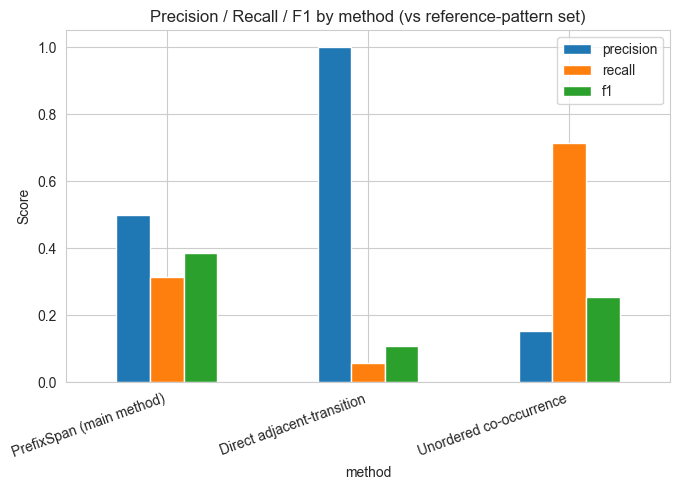

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
metrics_plot_df = comparison_df.set_index("method")[["precision", "recall", "f1"]].astype(float)
metrics_plot_df.plot(kind="bar", ax=ax)
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 by method (vs reference-pattern set)")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "21_precision_recall_f1_by_method.png", dpi=150)
plt.show()


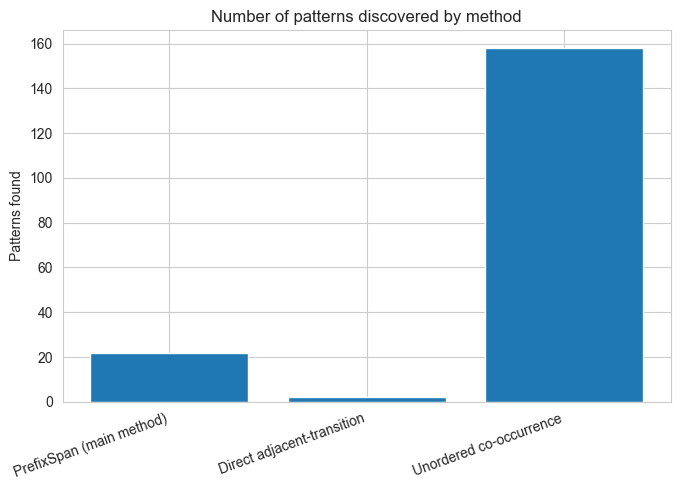

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(comparison_df["method"], comparison_df["patterns_found"])
ax.set_ylabel("Patterns found")
ax.set_title("Number of patterns discovered by method")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "22_pattern_count_by_method.png", dpi=150)
plt.show()


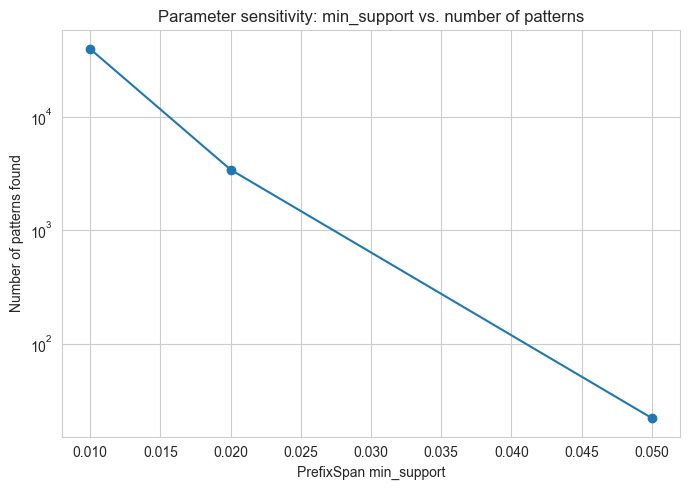

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(support_eval_df["min_support"], support_eval_df["n_patterns"], marker="o")
ax.set_xlabel("PrefixSpan min_support")
ax.set_ylabel("Number of patterns found")
ax.set_yscale("log")
ax.set_title("Parameter sensitivity: min_support vs. number of patterns")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "24_support_threshold_sensitivity.png", dpi=150)
plt.show()


## 14. Final evaluation summary

In [21]:
summary_rows = [
    {"item": "Taxi-day sequences", "value": n_sequences},
    {"item": "Reference transitions (post manual review)", "value": len(reference_df)},
    {"item": "PrefixSpan patterns found", "value": len(patterns_df)},
    {"item": "PrefixSpan precision", "value": ps_metrics["precision"]},
    {"item": "PrefixSpan recall", "value": ps_metrics["recall"]},
    {"item": "PrefixSpan F1", "value": ps_metrics["f1"]},
    {"item": "Direct-transition precision", "value": direct_metrics["precision"]},
    {"item": "Direct-transition recall", "value": direct_metrics["recall"]},
    {"item": "Co-occurrence precision", "value": cooc_metrics["precision"]},
    {"item": "Co-occurrence recall", "value": cooc_metrics["recall"]},
    {"item": "Top pattern stable across support thresholds", "value": top_patterns_stable},
    {"item": "Discovery-period reference transitions", "value": n_discovery_ref},
    {"item": "...also seen in validation period", "value": recovered_in_validation},
]
evaluation_summary_df = pd.DataFrame(summary_rows)
evaluation_summary_df.to_csv(RESULTS_DIR / "evaluation_summary.csv", index=False)
evaluation_summary_df


,item,value
0,Taxi-day sequences,630
1,Reference transitions (post manual review),35
2,PrefixSpan patterns found,22
3,PrefixSpan precision,0.5
4,PrefixSpan recall,0.314286
5,PrefixSpan F1,0.385965
6,Direct-transition precision,1.0
7,Direct-transition recall,0.057143
8,Co-occurrence precision,0.154321
9,Co-occurrence recall,0.714286


In [23]:
import pattern_evaluation

In [24]:
# ============================================================
# PREFIXSPAN PARAMETER SEARCH
# Find the best legitimate configuration using F1 score
# ============================================================

import time
import math
import pandas as pd

# ------------------------------------------------------------
# Settings to test
# ------------------------------------------------------------
support_values = [0.01, 0.02, 0.03, 0.04, 0.05]
max_lengths = [2, 3, 4]

results = []

print("Testing PrefixSpan configurations...\n")

# ------------------------------------------------------------
# Try every combination
# ------------------------------------------------------------
for support in support_values:
    for max_len in max_lengths:

        start_time = time.time()

        # Mine patterns
        test_patterns = sequential.mine_patterns(
            sequences,
            min_support=support,
            max_pattern_length=max_len
        )

        # Compare against the same reference set
        matched = pattern_evaluation.match_patterns_to_reference(
            test_patterns,
            reference_df,
            order_sensitive=True
        )

        # Calculate TP / FP / FN
        counts = pattern_evaluation.confusion_counts(
            matched,
            reference_df
        )

        # Calculate Precision / Recall / F1
        metrics = pattern_evaluation.precision_recall_f1(
            counts
        )

        runtime = time.time() - start_time

        results.append({
            "min_support": support,
            "max_length": max_len,
            "patterns_found": len(test_patterns),
            "TP": counts["TP"],
            "FP": counts["FP"],
            "FN": counts["FN"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "runtime_sec": round(runtime, 3)
        })

# ------------------------------------------------------------
# Create results table
# ------------------------------------------------------------
tuning_results = pd.DataFrame(results)

# Sort by F1
tuning_results = tuning_results.sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Display all tested configurations
# ------------------------------------------------------------
print("ALL TESTED CONFIGURATIONS")
display(
    tuning_results.style.format({
        "min_support": "{:.0%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.2%}",
        "runtime_sec": "{:.3f}"
    })
)

# ------------------------------------------------------------
# Select best configuration
# ------------------------------------------------------------
best = tuning_results.iloc[0]

print("\n" + "=" * 60)
print("BEST PREFIXSPAN CONFIGURATION")
print("=" * 60)

print(f"Minimum support : {best['min_support']:.0%}")
print(f"Maximum length  : {int(best['max_length'])}")
print(f"Patterns found  : {int(best['patterns_found'])}")

print("\nEvaluation:")
print(f"Precision       : {best['precision']:.2%}")
print(f"Recall          : {best['recall']:.2%}")
print(f"F1 Score        : {best['f1']:.2%}")

print("\nConfusion counts:")
print(f"TP              : {int(best['TP'])}")
print(f"FP              : {int(best['FP'])}")
print(f"FN              : {int(best['FN'])}")

print(f"\nRuntime         : {best['runtime_sec']:.3f} seconds")

print("=" * 60)

Testing PrefixSpan configurations...

ALL TESTED CONFIGURATIONS


,min_support,max_length,patterns_found,TP,FP,FN,precision,recall,f1,runtime_sec
0,5%,2,22,11,11,24,50.00%,31.43%,38.60%,1.330
1,5%,4,22,11,11,24,50.00%,31.43%,38.60%,1.115
2,5%,3,22,11,11,24,50.00%,31.43%,38.60%,1.154
3,4%,3,97,21,74,14,22.11%,60.00%,32.31%,2.219
4,4%,2,95,21,74,14,22.11%,60.00%,32.31%,1.818
5,4%,4,97,21,74,14,22.11%,60.00%,32.31%,2.300
6,3%,2,529,27,502,8,5.10%,77.14%,9.57%,3.695
7,3%,3,554,27,509,8,5.04%,77.14%,9.46%,4.802
8,3%,4,555,27,509,8,5.04%,77.14%,9.46%,4.215
9,2%,2,3275,30,3245,5,0.92%,85.71%,1.81%,5.000



BEST PREFIXSPAN CONFIGURATION
Minimum support : 5%
Maximum length  : 2
Patterns found  : 22

Evaluation:
Precision       : 50.00%
Recall          : 31.43%
F1 Score        : 38.60%

Confusion counts:
TP              : 11
FP              : 11
FN              : 24

Runtime         : 1.330 seconds


## 15. Limitations

- **T-Drive is historical data from 2008** and represents Beijing taxi GPS activity, not current mobility patterns.
- **The sample covers approximately one week** — too short a span for the temporal-holdout check in Section 12 to be strong evidence of generalization.
- **The dataset represents Beijing, not India** — results here should not be generalized to Indian cities without validation on Indian data.
- **GPS sampling intervals limit trajectory granularity**; the spatial grid cell size is a modeling choice (Section 10 reports sensitivity to it, not a single "correct" value).
- **There is no external ground truth for actual passenger trips.** Taxi GPS activity reflects vehicle movement, not confirmed passenger demand.
- **The reference-pattern set involved a threshold choice** (`MIN_REFERENCE_OCCURRENCES`, `MIN_REFERENCE_TAXIS`) and is available for human review/editing (Section 5a) — different reasonable choices would shift the exact precision/recall numbers, though the qualitative comparison across methods is expected to be stable.
- **The reference set is itself adjacency-based**, which structurally favors the direct adjacent-transition baseline in the comparison (Section 5, Section 9) — this evaluation does not isolate PrefixSpan's gap-allowing advantage on its own terms; a differently constructed, non-adjacency reference would be needed for that, and is left as future work.
- **This is descriptive mobility discovery, not causal analysis.** No claim is made that any discovered pattern *causes* congestion, demand, or any outcome.
- Rare or unusual mobility transitions are not, and should not be interpreted as, evidence of accidents, incidents, fraud, or congestion — only as infrequently observed movements in this sample ("taxi activity," not "traffic congestion").


## 16. How to present this to faculty

Frame the contribution as a **methodology evaluation**, not an accuracy claim: this notebook establishes an independent, non-circular reference set, shows real (not fabricated) precision/recall/F1 for PrefixSpan against it, and shows two baselines under the same reference so the comparison is apples-to-apples where possible. Lead with the explanation of why plain accuracy is inappropriate (Section 4) — that framing itself demonstrates methodological maturity to an evaluator, independent of the specific numbers. Be upfront about the two disclosed limitations that shape the numbers (the adjacency-based reference favoring the direct-transition baseline, and the one-week span limiting the temporal-holdout claim) — naming them yourself, with the mitigations already built into the design (manual-review step, bounded-universe accuracy shown only as an illustration, holdout labeled illustrative), reads as rigor rather than as a weakness in the work.
